/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V3_Large_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V3_Large_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-8738ca79.pth
100%|██████████| 21.1M/21.1M [00:00<00:00, 139MB/s]


Epoch 1/20 - Train Loss: 0.3924 Acc: 0.8590 - Val Loss: 2.1944 Acc: 0.6071
Epoch 2/20 - Train Loss: 0.1633 Acc: 0.9518 - Val Loss: 1.5522 Acc: 0.7214
Epoch 3/20 - Train Loss: 0.1274 Acc: 0.9587 - Val Loss: 0.6315 Acc: 0.8643
Epoch 4/20 - Train Loss: 0.1127 Acc: 0.9686 - Val Loss: 0.5155 Acc: 0.8179
Epoch 5/20 - Train Loss: 0.0539 Acc: 0.9845 - Val Loss: 0.8824 Acc: 0.8643
Epoch 6/20 - Train Loss: 0.0583 Acc: 0.9855 - Val Loss: 0.3407 Acc: 0.9000
Epoch 7/20 - Train Loss: 0.0331 Acc: 0.9908 - Val Loss: 0.3194 Acc: 0.9071
Epoch 8/20 - Train Loss: 0.0223 Acc: 0.9937 - Val Loss: 0.0475 Acc: 0.9821
Epoch 9/20 - Train Loss: 0.0742 Acc: 0.9766 - Val Loss: 0.6782 Acc: 0.7929
Epoch 10/20 - Train Loss: 0.0779 Acc: 0.9756 - Val Loss: 0.2412 Acc: 0.9500
Epoch 11/20 - Train Loss: 0.0313 Acc: 0.9901 - Val Loss: 0.1879 Acc: 0.9536
Epoch 12/20 - Train Loss: 0.0067 Acc: 0.9983 - Val Loss: 0.1413 Acc: 0.9679
Epoch 13/20 - Train Loss: 0.0127 Acc: 0.9960 - Val Loss: 0.2008 Acc: 0.9393
Epoch 14/20 - Train L

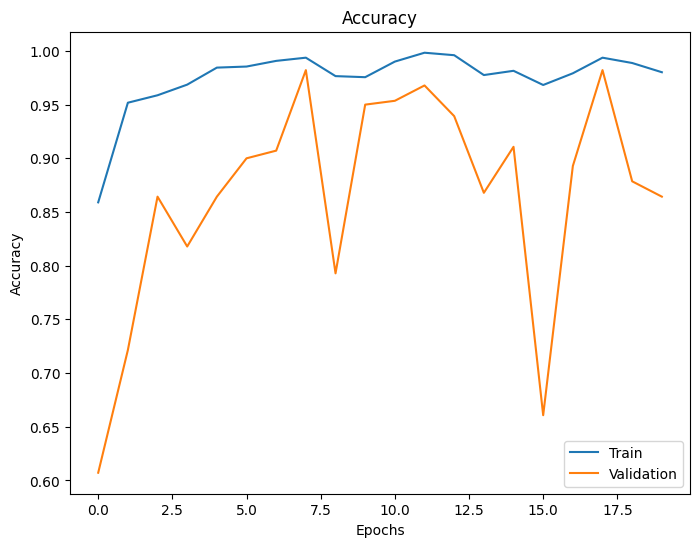

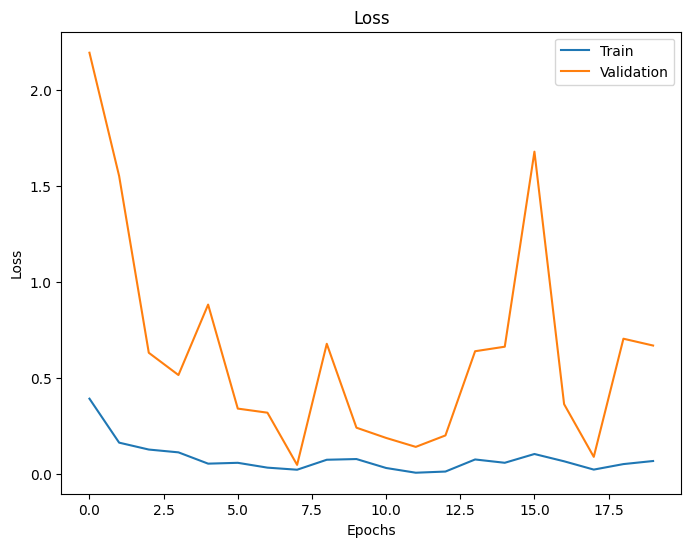

/tmp/ipykernel_30/2908626345.py:128: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('best_model.pth'))


Classification Report:
              precision    recall  f1-score   support

         ALM       1.00      0.92      0.96        26
   M in Situ       0.92      0.96      0.94        24
          NM       1.00      1.00      1.00        18
         SSM       0.95      1.00      0.98        20

    accuracy                           0.97        88
   macro avg       0.97      0.97      0.97        88
weighted avg       0.97      0.97      0.97        88

Confusion Matrix:


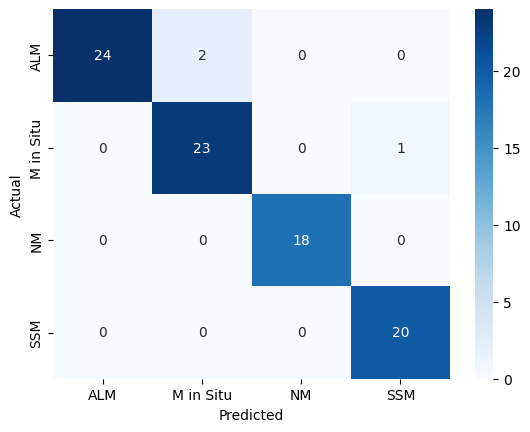

In [1]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Define transforms
transform = {
    'train': transforms.Compose([
        transforms.Resize((640, 640)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'valid': transforms.Compose([
        transforms.Resize((640, 640)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
}

# Load datasets
train_dataset = datasets.ImageFolder('/kaggle/input/save-dataset/SAVE/train', transform=transform['train'])
valid_dataset = datasets.ImageFolder('/kaggle/input/save-dataset/SAVE/valid', transform=transform['valid'])
test_dataset = datasets.ImageFolder('/kaggle/input/save-dataset/SAVE/test', transform=transform['valid'])

# DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Model (YOLO Backbone adapted for classification)
class YOLOv11Classifier(nn.Module):
    def __init__(self, num_classes):
        super(YOLOv11Classifier, self).__init__()
        self.backbone = models.mobilenet_v3_large(pretrained=True)
        self.backbone.classifier[-1] = nn.Linear(self.backbone.classifier[-1].in_features, num_classes)
    
    def forward(self, x):
        return self.backbone(x)

num_classes = 4
model = YOLOv11Classifier(num_classes).to(device)

# Loss and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Training and Validation Loop
def train_and_validate(model, train_loader, valid_loader, criterion, optimizer, num_epochs=20):
    best_acc = 0.0
    train_acc_history, train_loss_history = [], []
    val_acc_history, val_loss_history = [], []
    
    for epoch in range(num_epochs):
        # Training Phase
        model.train()
        train_loss, train_corrects = 0.0, 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            train_corrects += torch.sum(preds == labels.data)
        
        train_epoch_loss = train_loss / len(train_dataset)
        train_epoch_acc = train_corrects.double() / len(train_dataset)
        train_loss_history.append(train_epoch_loss)
        train_acc_history.append(train_epoch_acc.item())
        
        # Validation Phase
        model.eval()
        val_loss, val_corrects = 0.0, 0
        with torch.no_grad():
            for inputs, labels in valid_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)
                _, preds = torch.max(outputs, 1)
                val_corrects += torch.sum(preds == labels.data)
        
        val_epoch_loss = val_loss / len(valid_dataset)
        val_epoch_acc = val_corrects.double() / len(valid_dataset)
        val_loss_history.append(val_epoch_loss)
        val_acc_history.append(val_epoch_acc.item())
        
        print(f"Epoch {epoch+1}/{num_epochs} - "
              f"Train Loss: {train_epoch_loss:.4f} Acc: {train_epoch_acc:.4f} - "
              f"Val Loss: {val_epoch_loss:.4f} Acc: {val_epoch_acc:.4f}")
        
        # Save the best model
        if val_epoch_acc > best_acc:
            best_acc = val_epoch_acc
            torch.save(model.state_dict(), 'best_model.pth')
    
    return train_acc_history, train_loss_history, val_acc_history, val_loss_history

# Train and validate the model
train_acc, train_loss, val_acc, val_loss = train_and_validate(model, train_loader, valid_loader, criterion, optimizer)

# Plot Loss and Accuracy
def plot_metrics(train_metric, val_metric, title, ylabel):
    plt.figure(figsize=(8, 6))
    plt.plot(train_metric, label='Train')
    plt.plot(val_metric, label='Validation')
    plt.title(title)
    plt.xlabel('Epochs')
    plt.ylabel(ylabel)
    plt.legend()
    plt.show()

plot_metrics(train_acc, val_acc, 'Accuracy', 'Accuracy')
plot_metrics(train_loss, val_loss, 'Loss', 'Loss')

# Test the model
def evaluate_model(model, test_loader):
    model.load_state_dict(torch.load('best_model.pth'))
    model.eval()
    all_preds, all_labels = [], []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    print("Classification Report:")
    print(classification_report(all_labels, all_preds, target_names=test_dataset.classes))
    
    print("Confusion Matrix:")
    cm = confusion_matrix(all_labels, all_preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=test_dataset.classes, yticklabels=test_dataset.classes)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

# Evaluate the model
evaluate_model(model, test_loader)
